# Model 06 · Will this programmer fix the bug or restart the server?
5-class classifier.

In [1]:
import sys
sys.path.insert(0, "../_shared")
try:
    import kit
except ImportError:
    from google.colab import files; files.upload(); import kit
from kit import *

## 1 · Dataset generator
Each strategy has its own utility. Fatigue pushes toward restarting and giving up, experience toward blaming dependencies,
Stack Overflow tabs toward more googling. Noise is added to every utility before sampling.

In [2]:
CLASSES = ["fix", "restart", "google", "blame", "giveup"]
def generate(n=10000, seed=SEED):
    r = np.random.default_rng(seed)
    d = pd.DataFrame({"severity": r.choice([1, 2, 3, 4, 5], n, p=[.2, .3, .25, .15, .1]),
        "error_len": np.round(np.clip(r.lognormal(4.3, .8, n), 10, 800)), "minutes": np.round(np.clip(np.exp(r.normal(3.6, 1.0, n)), 1, 600)),
        "so_tabs": np.clip(r.poisson(4, n), 0, 30), "coffee": np.clip(r.poisson(2, n), 0, 8),
        "sleep": np.round(np.clip(r.normal(6.5, 1.4, n), 2, 10), 1), "experience": np.round(np.clip(np.exp(r.normal(.9, .9, n)), 0, 15) * 2) / 2})
    s, e, m, sl, c, t, L_ = d.severity, d.experience, d.minutes, d.sleep, d.coffee, d.so_tabs, d.error_len
    U = np.column_stack([
        0.9 + 0.35 * (sl - 6.5) + 0.12 * e - 0.006 * m - 0.25 * s + 0.1 * c - 0.0015 * L_,
        0.2 + 0.004 * m + 0.15 * (s - 3) + 0.0015 * L_ - 0.05 * (sl - 6.5),
        0.7 + 0.10 * t - 0.10 * e + 0.0012 * L_ - 0.002 * m,
        -0.7 + 0.06 * e + 0.003 * L_ + 0.002 * m + 0.9 * ((e > 4) & (m > 90)),
        -0.9 + 0.007 * m + 0.25 * (6.5 - sl).clip(0) - 0.1 * c + 0.6 * ((m > 240) & (sl < 5.5))])
    U = 1.8 * U
    y = sample_categorical(softmax(U + r.normal(0, 0.4, U.shape)), r)
    d["strategy"] = np.array(CLASSES)[y]; d["oracle_hit"] = (softmax(U).argmax(1) == y).astype(int); return d

In [3]:
df = generate(10000); df.drop(columns="oracle_hit").to_csv("dataset.csv", index=False)
print(df.shape, "| oracle accuracy:", round(df.oracle_hit.mean(), 3)); df.strategy.value_counts(normalize=True).round(3)

(10000, 9) | oracle accuracy: 0.522


strategy
google     0.362
fix        0.259
restart    0.236
blame      0.093
giveup     0.050
Name: proportion, dtype: float64

## 2 · Cleaning + EDA

nulls: 0 | duplicates: 0


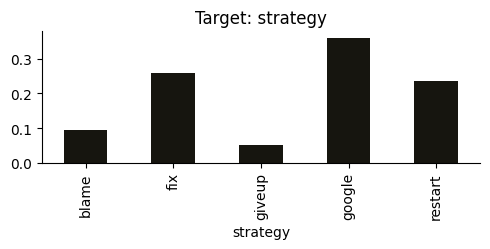

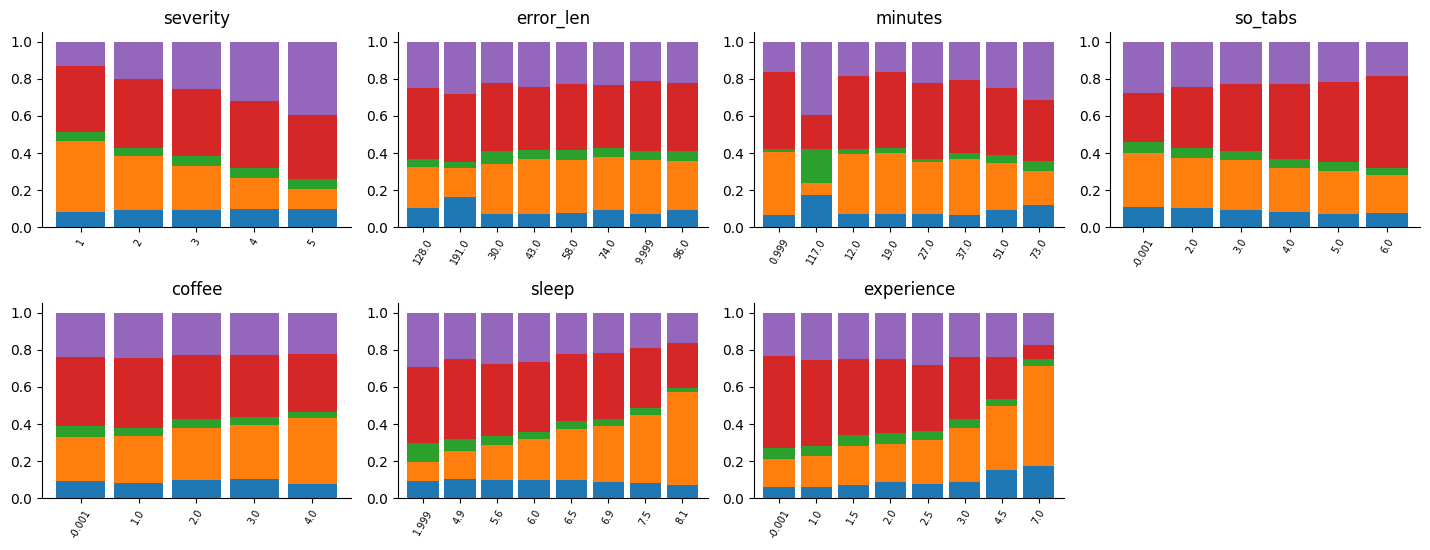

In [4]:
print("nulls:", int(df.isna().sum().sum()), "| duplicates:", int(df.duplicated().sum()))
INPUTS = [Num("severity", 1, 5), Num("error_len", 0, 800, "log1p"), Num("minutes", 0, 600), Num("so_tabs", 0, 30), Num("coffee", 0, 8), Num("sleep", 0, 12), Num("experience", 0, 15)]
RAW = [s["name"] for s in INPUTS]; eda(df, "strategy", RAW, "multiclass")

## 3 · Features, split, train

In [5]:
IDX = {c: i for i, c in enumerate(CLASSES)}
fz = Featurizer(INPUTS); tr, va, te = split3(df, "strategy")
Xtr, Xva, Xte = fz.transform(tr), fz.transform(va), fz.transform(te)
ytr, yva, yte = (x.strategy.map(IDX).to_numpy() for x in (tr, va, te))
best, best_name, table = train_classifier(Xtr, ytr, Xva, yva, depth=8, leaf=30)
print("selected:", best_name); table.round(4)

selected: Logistic Regression


,model,val_log_loss,val_accuracy
0,Logistic Regression,1.158,0.532
1,Random Forest,1.213,0.508


## 4 · Test evaluation + importance

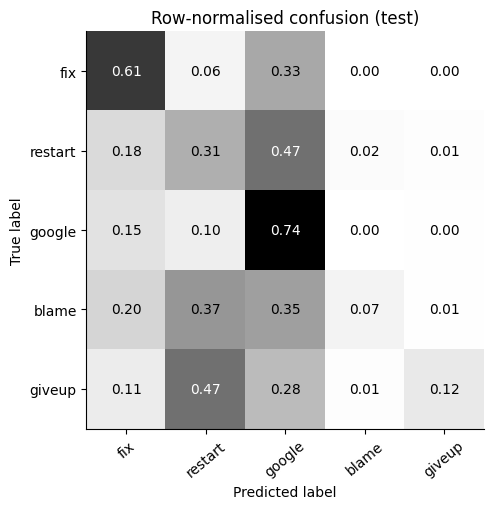

{'accuracy': 0.514,
 'macro_f1': 0.3757,
 'log_loss': 1.18,
 'top3_accuracy': 0.9147,
 'oracle_accuracy': 0.5173}

In [6]:
m = report_multiclass(best, Xte, yte, CLASSES); m["oracle_accuracy"] = round(float(te.oracle_hit.mean()), 4); m

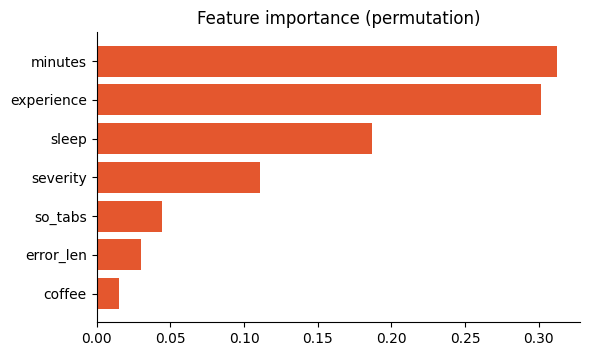

{'minutes': 0.3123,
 'experience': 0.3013,
 'sleep': 0.1865,
 'severity': 0.1106,
 'so_tabs': 0.0442,
 'error_len': 0.0299,
 'coffee': 0.0152}

In [7]:
imp = group_importance(best.predict_proba, Xte, yte, fz.groups, lambda y, p: log_loss(y, p, labels=list(range(5))))
plot_importance(imp); imp

In [8]:
ex = pd.DataFrame([dict(severity=4, error_len=420, minutes=200, so_tabs=9, coffee=5, sleep=4.5, experience=3),
                   dict(severity=2, error_len=40, minutes=10, so_tabs=1, coffee=2, sleep=8, experience=6)])
ex[CLASSES] = best.predict_proba(fz.transform(ex)).round(3); ex

,severity,error_len,minutes,so_tabs,coffee,sleep,experience,fix,restart,google,blame,giveup
0,4,420,200,9,5,4.5,3,0.002,0.570,0.223,0.129,0.077
1,2,40,10,1,2,8.0,6,0.858,0.043,0.060,0.035,0.004


## 5 · Export + verify

In [9]:
heads = {"strategy": export_head(best, labels=CLASSES)}
meta = make_metadata("v1.0", SEED, len(df), {"train": len(tr), "val": len(va), "test": len(te)},
    {"strategy": {"algorithm": best_name, "task": "multiclass", "metrics": m, "candidates": table.round(4).to_dict("records")}}, imp,
    ["Synthetic data. Real debugging is chaos with a coffee habit.", "Accuracy is capped by sampling noise; see oracle_accuracy."], "generate() in this notebook")
write_artifacts("model", "programmer-debug", "Will this programmer fix the bug or restart the server?", fz, tr, heads, {"strategy": best}, meta, te[RAW])

wrote model (42 KB total) | export error vs sklearn: {'strategy': 1.975816843469147e-09}


{'strategy': 1.975816843469147e-09}